# Predicting credit card default

**The question.** A card issuer wants to know, before next month's statement,
which customers are likely to miss their payment. With that, it can decide
whether to keep extending credit to someone — approve a limit increase, send
the case to an analyst, or decline — instead of finding out after the money
is gone.

**The data.** 30,000 real credit card customers of a Taiwanese bank, 2005:
each customer's credit limit and six months of bills, payments and repayment
status, plus whether they missed the *following* month's payment
([UCI, Yeh 2009](https://doi.org/10.24432/C55S3H), CC BY 4.0).

**The plan.** Look at the data → set a test set aside → choose a model using
only the rest → score the test set once → turn predictions into decisions →
explain them → check they are fair → be clear about what this can't tell us.

Every function used here lives in `src/crediwise/`, the same code the web
service runs, so nothing below is notebook-only logic.

In [1]:
import sys, json, warnings
from pathlib import Path

warnings.filterwarnings("ignore")

try:
    import crediwise  # noqa: F401
except ImportError:  # running from notebooks/ without PYTHONPATH=src
    sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from sklearn.metrics import roc_curve
from sklearn.model_selection import cross_val_score, train_test_split

from crediwise import config as cfg, data, evaluate, fairness
from crediwise.explain import Explainer, REASONS
from crediwise.model import baseline_model, build_search, cv_splitter
from crediwise.policy import DecisionPolicy

pd.set_option("display.float_format", "{:,.3f}".format)

# Chart style: light surface, hairline grid, one blue series (orange as the
# second series). The two colours were checked for colour-blind separation.
SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.family": "sans-serif", "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlepad": 10, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "legend.frameon": False, "lines.linewidth": 2, "lines.solid_capstyle": "round",
})

## 1. The data

One row per customer. The model only gets what the bank already holds about how
each customer has used their card — never their sex, marital status, age or
education (section 7 explains why, and checks fairness anyway).

In [2]:
raw = data.load_raw()
df = data.load_dataset()
print(f"{len(raw):,} customers in the source; {len(raw) - len(df)} duplicate records dropped -> {len(df):,}")
print(f"{df[cfg.TARGET].mean():.1%} missed their payment the following month")

30,000 customers in the source; 35 duplicate records dropped -> 29,965
22.1% missed their payment the following month


Here is one customer's history. **Repayment status** is a code: −1 means paid in
full and 1–9 means that many months late. The two most common values, −2 and 0,
are not defined in the source documentation. They look like "no balance" and
"paid at least the minimum", but we don't invent a meaning: the model just treats
the codes as ordered numbers.

In [3]:
c = df.iloc[0]
print(f"Credit limit {c.credit_limit:,.0f}  |  missed next payment: {'yes' if c[cfg.TARGET] else 'no'}")
pd.DataFrame({
    "repayment status": [int(c[f"status_{m}"]) for m in cfg.MONTHS],
    "bill":             [int(c[f"bill_{m}"]) for m in cfg.MONTHS],
    "paid":             [int(c[f"paid_{m}"]) for m in cfg.MONTHS],
}, index=[m.capitalize() for m in cfg.MONTHS])

Credit limit 20,000  |  missed next payment: yes


,repayment status,bill,paid
Sep,2,3913,0
Aug,2,3102,689
Jul,-1,689,0
Jun,-1,0,0
May,-2,0,0
Apr,-2,0,0


From that history we compute five summaries — months paid late, worst delay,
how much of the limit is in use (latest and average), and how much of the last
bill was paid. They help a little with accuracy, and they let the model explain
itself in plain language later.

Does past lateness actually predict default? Strongly:

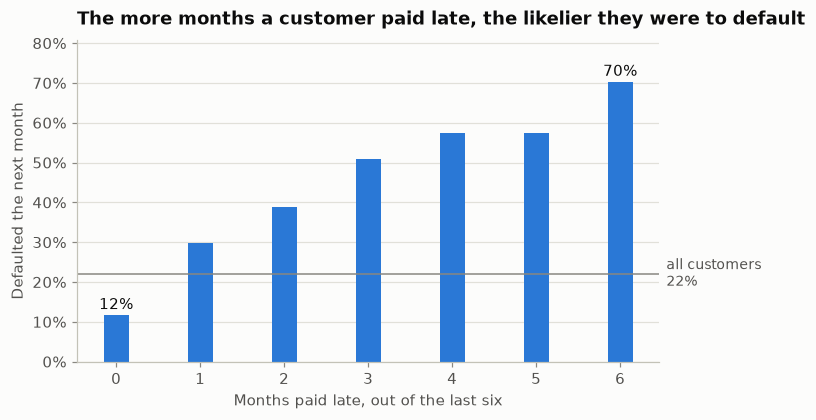

,customers,default_rate
months_late,,
0,19918,0.117
1,4405,0.299
2,1899,0.388
3,1154,0.509
4,951,0.573
5,298,0.574
6,1340,0.703


In [4]:
by_late = df.groupby("months_late")[cfg.TARGET].agg(customers="size", default_rate="mean")
overall = df[cfg.TARGET].mean()

fig, ax = plt.subplots(figsize=(7.2, 3.8))
ax.bar(by_late.index, by_late["default_rate"], width=0.3, color=BLUE)
ax.axhline(overall, color=MUTED, linewidth=1)
ax.text(6.55, overall, f"all customers\n{overall:.0%}", color=INK_2, ha="left", va="center",
        fontsize=9, clip_on=False)
for x in (by_late.index.min(), by_late.index.max()):
    ax.text(x, by_late.loc[x, "default_rate"] + 0.015, f"{by_late.loc[x, 'default_rate']:.0%}",
            ha="center", color=INK, fontsize=9.5)
ax.set_title("The more months a customer paid late, the likelier they were to default")
ax.set_xlabel("Months paid late, out of the last six")
ax.set_ylabel("Defaulted the next month")
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_ylim(0, by_late["default_rate"].max() * 1.15)
ax.grid(axis="x", visible=False)
fig.subplots_adjust(right=0.86)
plt.show()
by_late

## 2. Set the test set aside — first

20% of customers are put away now and not touched until section 4. Every choice
before then is made on the other 80% using cross-validation, so the final score
measures performance on customers the model, and the person building it, never saw.

In [5]:
train, test = train_test_split(df, test_size=cfg.TEST_SIZE, stratify=df[cfg.TARGET],
                               random_state=cfg.RANDOM_STATE)
X_train, y_train = train[cfg.FEATURES], train[cfg.TARGET]
X_test, y_test = test[cfg.FEATURES], test[cfg.TARGET]
print(f"train {len(train):,} customers  |  test {len(test):,} customers (held back)")

train 23,972 customers  |  test 5,993 customers (held back)


## 3. Choose a model, using training data only

Why not judge by accuracy? Because 22% default, so a "model" that predicts
*nobody defaults* is 78% accurate and useless. We use **AUC** instead: the chance
the model ranks a random defaulter as riskier than a random customer who repaid
(0.5 = coin flip, 1.0 = perfect).

A simple, transparent benchmark first, then gradient boosting with a search over
its settings. Both are scored by 5-fold cross-validation on the training data.

In [6]:
lr_cv = cross_val_score(baseline_model(), X_train, y_train, cv=cv_splitter(),
                        scoring="roc_auc", n_jobs=-1)
search = build_search().fit(X_train, y_train)
model = search.best_estimator_
gb_std = search.cv_results_["std_test_score"][search.best_index_]

pd.DataFrame({
    "cross-validated AUC": [lr_cv.mean(), search.best_score_],
    "± (spread across folds)": [lr_cv.std(), gb_std],
}, index=["Logistic regression (benchmark)", "Gradient boosting (tuned)"])

,cross-validated AUC,± (spread across folds)
Logistic regression (benchmark),0.756,0.009
Gradient boosting (tuned),0.788,0.008


Gradient boosting wins clearly, so that's the model. Its settings came from
trying 40 combinations; the best was only slightly better than the defaults —
the big gain was choosing the model type.

## 4. Score the test set — once

In [7]:
p_test = model.predict_proba(X_test)[:, 1]
p_lr = baseline_model().fit(X_train, y_train).predict_proba(X_test)[:, 1]
scores = evaluate.score_metrics(y_test, p_test)

print(f"Test AUC {scores['auc']:.3f}  (benchmark {evaluate.score_metrics(y_test, p_lr)['auc']:.3f};"
      f" cross-validation estimated {search.best_score_:.3f})")
riskiest = p_test >= np.quantile(p_test, 0.9)
print(f"Of the 10% of test customers the model ranks riskiest, {y_test[riskiest].mean():.0%} defaulted"
      f" (against {scores['default_rate']:.0%} overall).")

Test AUC 0.777  (benchmark 0.747; cross-validation estimated 0.788)
Of the 10% of test customers the model ranks riskiest, 69% defaulted (against 22% overall).


The test score is a little below the cross-validated estimate. That's normal for
a single test set of ~6,000 customers — and it's the number to quote, because the
test set played no part in any decision.

The curves show the trade-off every lender faces: catching more defaulters means
wrongly flagging more good customers. A better model reaches higher sooner.

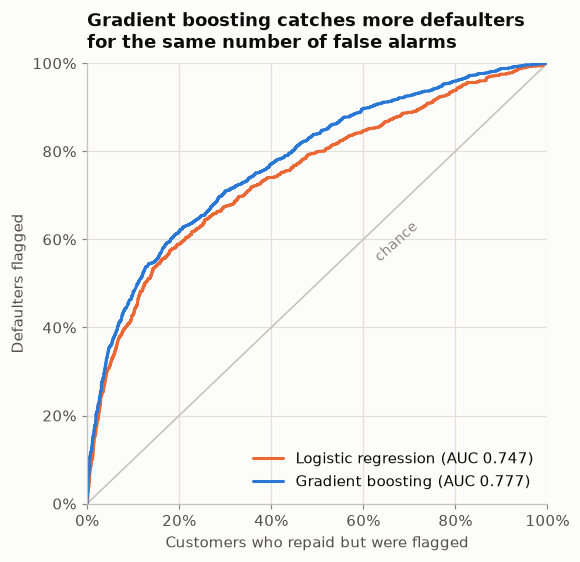

In [8]:
fig, ax = plt.subplots(figsize=(5.4, 5.2))
ax.plot([0, 1], [0, 1], color=AXIS, linewidth=1)
ax.text(0.62, 0.55, "chance", color=MUTED, fontsize=9, rotation=42)
for p, color, name in [(p_lr, ORANGE, "Logistic regression"), (p_test, BLUE, "Gradient boosting")]:
    fpr, tpr, _ = roc_curve(y_test, p)
    auc = evaluate.score_metrics(y_test, p)["auc"]
    ax.plot(fpr, tpr, color=color, label=f"{name} (AUC {auc:.3f})")
ax.set_title("Gradient boosting catches more defaulters\nfor the same number of false alarms")
ax.set_xlabel("Customers who repaid but were flagged")
ax.set_ylabel("Defaulters flagged")
for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.legend(loc="lower right")
plt.show()

## 5. Can the probabilities be taken at face value?

A decision rule needs real probabilities: if the model says 30%, about 30 in 100
such customers should default. Grouping test customers by predicted risk and
comparing with what actually happened:

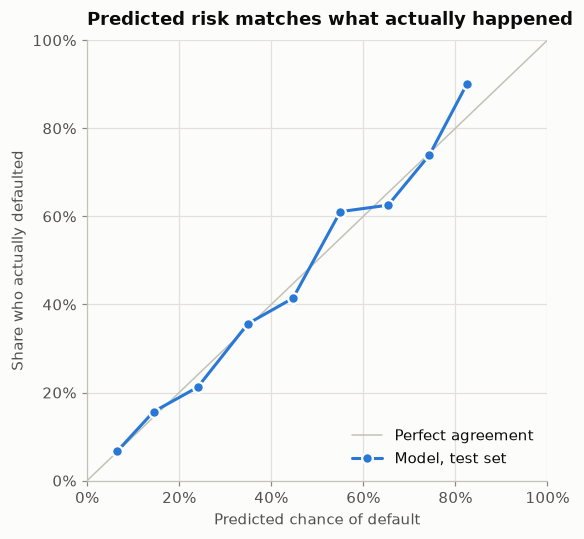

Average gap between predicted and actual: 1.3%


,bin,n,predicted,observed
0,"(-0.001, 0.1]",1864,0.066,0.067
1,"(0.1, 0.2]",1987,0.144,0.157
2,"(0.2, 0.3]",787,0.240,0.212
3,"(0.3, 0.4]",376,0.349,0.356
4,"(0.4, 0.5]",280,0.447,0.414
5,"(0.5, 0.6]",149,0.550,0.611
6,"(0.6, 0.7]",259,0.654,0.625
7,"(0.7, 0.8]",261,0.744,0.739
8,"(0.8, 0.9]",30,0.825,0.900


In [9]:
cal = evaluate.calibration_table(y_test, p_test)

fig, ax = plt.subplots(figsize=(5.4, 5.2))
ax.plot([0, 1], [0, 1], color=AXIS, linewidth=1, label="Perfect agreement")
ax.plot(cal["predicted"], cal["observed"], color=BLUE, marker="o", markersize=7,
        markeredgecolor=SURFACE, markeredgewidth=1.5, label="Model, test set")
ax.legend(loc="lower right")
ax.set_title("Predicted risk matches what actually happened")
ax.set_xlabel("Predicted chance of default")
ax.set_ylabel("Share who actually defaulted")
for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
plt.show()
print(f"Average gap between predicted and actual: {scores['calibration_error']:.1%}")
cal

Close enough that no extra calibration step is needed. (One was tried during
development; it made things slightly worse.) The highest bins hold few customers,
so they wobble more.

## 6. From a probability to a decision

The model estimates risk; a separate **policy** decides what to do. Lending to a
customer who defaults is assumed to cost 5× as much as turning away one who would
have repaid. That makes approving worthwhile while the risk is under 1 in 6:

- **approve** below 16.7%
- **decline** at 50% or more (likelier to default than not)
- **refer** to an analyst in between

The 5:1 ratio is illustrative. A real lender would plug in its own losses and
margins, and the thresholds follow automatically — without retraining the model.

In [10]:
policy = DecisionPolicy()
decisions = policy.decide(p_test)
o = evaluate.decision_metrics(y_test, decisions)

print(f"Approve {o['approved_share']:.0%}  |  refer {o['referred_share']:.0%}  |  decline {o['declined_share']:.0%}")
print(f"Approved customers default at {o['default_rate_among_approved']:.1%}, "
      f"against {o['default_rate_if_all_approved']:.1%} if everyone were approved.")
print(f"{o['defaulters_not_approved']:.0%} of defaulters are kept from automatic approval;"
      f" {o['payers_declined']:.1%} of customers who repaid are declined.")

Approve 57%  |  refer 32%  |  decline 12%
Approved customers default at 10.4%, against 22.1% if everyone were approved.
73% of defaulters are kept from automatic approval; 4.8% of customers who repaid are declined.


## 7. Why did it decide that?

US lending rules require a lender that turns someone down to give the main
reasons. **SHAP** splits each prediction into the contribution of each feature,
exactly: the pieces add up to the model's output. Averaged across the test set,
here is what matters most:

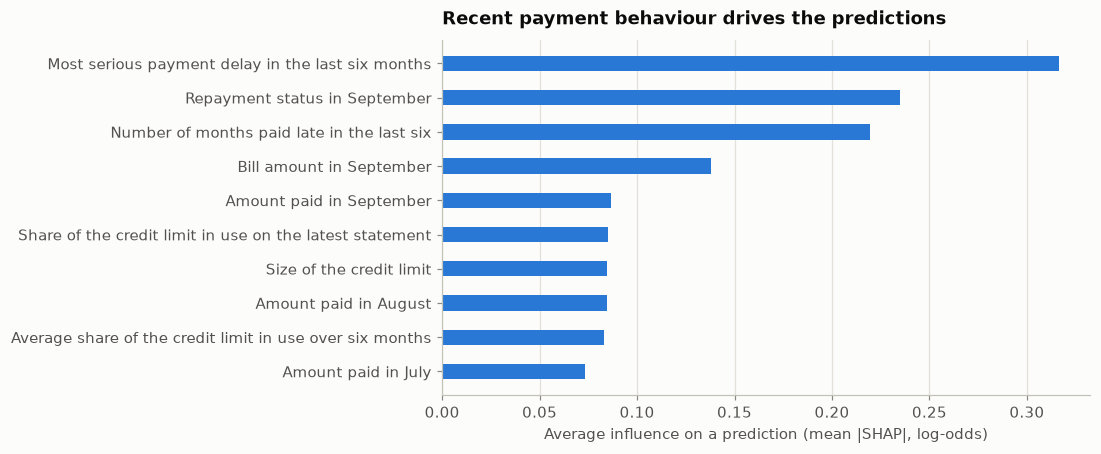

,feature,mean_abs_shap,meaning
0,worst_status,0.317,Most serious payment delay in the last six months
1,status_sep,0.235,Repayment status in September
2,months_late,0.220,Number of months paid late in the last six
3,bill_sep,0.138,Bill amount in September
4,paid_sep,0.087,Amount paid in September
5,utilization,0.085,Share of the credit limit in use on the latest...
6,credit_limit,0.085,Size of the credit limit
7,paid_aug,0.085,Amount paid in August
8,avg_utilization,0.083,Average share of the credit limit in use over ...
9,paid_jul,0.073,Amount paid in July


In [11]:
explainer = Explainer(model)
imp = explainer.global_importance(X_test).head(10)

fig, ax = plt.subplots(figsize=(7.6, 4.2))
ax.barh([REASONS[f] for f in imp["feature"]][::-1], imp["mean_abs_shap"][::-1],
        height=0.45, color=BLUE)
ax.set_title("Recent payment behaviour drives the predictions")
ax.set_xlabel("Average influence on a prediction (mean |SHAP|, log-odds)")
ax.grid(axis="y", visible=False)
plt.show()
imp.assign(meaning=[REASONS[f] for f in imp["feature"]])

And for a single declined customer — the reasons the service would return:

In [12]:
declined = X_test[decisions == "decline"].iloc[[0]]
print(f"Predicted chance of default: {model.predict_proba(declined)[0, 1]:.0%} -> decline")
for r in explainer.reasons(declined)[0]:
    print(f"  - {r['reason']}")

Predicted chance of default: 54% -> decline
  - Most serious payment delay in the last six months
  - Repayment status in September
  - Number of months paid late in the last six
  - Amount paid in August


## 8. Is it fair?

The model never sees sex, marital status, age or education. Including the first
three made no difference to accuracy (CV AUC 0.7844 with, 0.7853 without), so they
were left out. But leaving a column out doesn't make a model fair — other
features can stand in for it. So we check **outcomes** for each group.

The fairest single question is: *among customers who did repay, did the model
approve them at similar rates?*

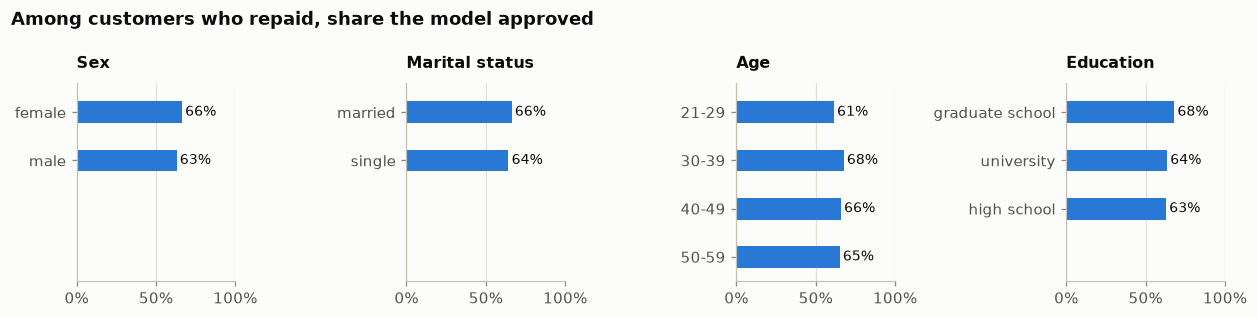

,approval_ratio,passes_four_fifths,repayment_ratio,amplification,equal_opportunity_gap
sex,0.941,True,0.953,0.988,0.034
marital_status,0.995,True,0.954,1.043,0.020
age_band,0.902,True,0.948,0.952,0.062
education,0.846,True,0.898,0.942,0.052


In [13]:
audit = fairness.audit(y_test, p_test, decisions, test.reset_index(drop=True), cfg.AUDIT_DIMENSIONS)
panels = [("sex", "Sex", None), ("marital_status", "Marital status", None),
          ("age_band", "Age", None), ("education", "Education",
          ["graduate_school", "university", "high_school"])]

fig, axes = plt.subplots(1, 4, figsize=(11.5, 2.9), sharex=True)
slots = 4  # every panel gets four slots, so bar thickness matches across panels
for ax, (dim, label, order) in zip(axes, panels):
    g = pd.DataFrame(audit[dim]["by_group"]).set_index("group")
    g = g.drop(index=[i for i in g.index if i == "unknown"]).reindex(order or sorted(g.index))
    vals = g["approval_rate_if_repaid"].to_numpy()
    ax.barh(range(len(vals)), vals, height=0.45, color=BLUE)
    ax.set_yticks(range(len(vals)), [i.replace("_", " ") for i in g.index])
    ax.set_ylim(slots - 0.5, -0.6)
    for y, v in enumerate(vals):
        ax.text(v + 0.02, y, f"{v:.0%}", va="center", fontsize=9, color=INK)
    ax.set_title(label, fontsize=10.5)
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.grid(axis="y", visible=False)
fig.suptitle("Among customers who repaid, share the model approved", x=0.01, ha="left",
             fontsize=11.5, fontweight="bold", color=INK)
fig.tight_layout()
plt.show()

pd.DataFrame({dim: audit[dim]["summary"] for dim, *_ in panels}).T[
    ["approval_ratio", "passes_four_fifths", "repayment_ratio", "amplification", "equal_opportunity_gap"]]

**Reading the table.** *approval_ratio* is the lowest group's approval rate over
the highest's; regulators' rule of thumb flags anything under 0.8. All four pass.
*amplification* compares that gap with the gap in who actually repaid: below 1
means the model makes approvals a bit more unequal than reality, above 1 less.

The one group worth watching:

In [14]:
age = pd.DataFrame(audit["age_band"]["by_group"]).set_index("group")
worst = age["approval_rate_if_repaid"].idxmin()
best = age["approval_rate_if_repaid"].idxmax()
print(f"Customers aged {worst} who repaid were approved {age.loc[worst, 'approval_rate_if_repaid']:.0%} of the time,"
      f" against {age.loc[best, 'approval_rate_if_repaid']:.0%} for ages {best}.")
print(f"The model predicts {age.loc[worst, 'predicted_default_rate']:.1%} of {worst}-year-olds will default;"
      f" {age.loc[worst, 'default_rate']:.1%} actually did. It is slightly too pessimistic about them.")
for d in cfg.AUDIT_DIMENSIONS:
    small = audit[d]["too_small_to_assess"]
    if small:
        print(f"Too few customers to assess ({d}):", ", ".join(f"{k} ({v})" for k, v in small.items()))

Customers aged 21-29 who repaid were approved 61% of the time, against 68% for ages 30-39.
The model predicts 23.6% of 21-29-year-olds will default; 21.7% actually did. It is slightly too pessimistic about them.
Too few customers to assess (marital_status): other (57), unknown (8)
Too few customers to assess (age_band): 60-79 (67)
Too few customers to assess (education): unknown (57), other (33)


The data also cannot test race, religion, national origin or receipt of public
assistance — they're not in it. See `docs/FAIRNESS.md`.

## 9. What this can't tell you

- **One bank, one country, one year (Taiwan, 2005).** Nothing here shows the model
  would work for another lender or today.
- **No test across time.** Every customer comes from the same six months, so we
  can't measure how quickly the model would go stale.
- **Two repayment codes are undocumented** (−2 and 0); they're used as ordered
  codes without guessing their meaning.
- **The decision costs are illustrative**, and the fairness check is limited to
  what the data contains.

## 10. Check: same numbers as the trained model

`make train` runs this same pipeline and saves the model the web service uses.
If it has been run, the numbers should agree exactly:

In [15]:
report_path = cfg.REPORT_DIR / "metrics.json"
if report_path.exists():
    saved = json.loads(report_path.read_text())["test"]
    for key in ["auc", "pr_auc", "brier", "calibration_error"]:
        assert abs(saved[key] - scores[key]) < 1e-9, key
    print("Matches reports/metrics.json:", {k: round(scores[k], 4) for k in ["auc", "pr_auc", "brier"]})
else:
    print("reports/metrics.json not found; run `make train` to compare.")

Matches reports/metrics.json: {'auc': 0.7768, 'pr_auc': 0.5538, 'brier': 0.1357}
